In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [39]:
data_folder = Path("../02_Data_Raw")

for file in data_folder.rglob("*"):
    if file.is_file():
        print(file, "|", file.stat().st_size, "bytes")

..\02_Data_Raw\Data01.csv | 2082370 bytes


In [45]:
df = pd.read_csv("../02_Data_Raw/Data01.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [47]:
df_audit = df.copy()

In [49]:
print("Number of rows:", df_audit.shape[0])
print("Number of columns:", df_audit.shape[1])

Number of rows: 6500
Number of columns: 10


In [51]:
display(df_audit.head())

,type,source,id,rating,num_token,sample_criteria,review_text,rating_bin,rating_cat,length_bin
0,teacher review,data1_19145,1_45_2639_18911,5.0,74,"Pos_(61.0, 81.0]",Dr. Zhong is a really good chemistry teacher. She taught the concepts really but you still have to self study if you...,"(4.0, 5.0]",Pos,"(61.0, 81.0]"
1,teacher review,data1_19145,1_206_452_3440,1.5,56,"Neg_(41.0, 61.0]",I have her for behav. neuro and she is terrible at explaining. Shows us almost irrelevant videos and doesn\'t unders...,"(0.999, 2.5]",Neg,"(41.0, 61.0]"
2,teacher review,data1_19145,1_93_2121_1031,1.0,77,"Neg_(61.0, 81.0]",the prof. is real crap. it is a shame that the university hires such profs.....he diesnt even know how to teach. he ...,"(0.999, 2.5]",Neg,"(61.0, 81.0]"
3,teacher review,data1_19145,1_89_50_4831,3.5,42,"Conf/Neu_(41.0, 61.0]","He is a great guy and is pretty funny in class. Lectures get boring and you use all your books. However, even though...","(2.5, 4.0]",Conf/Neu,"(41.0, 61.0]"
4,teacher review,data1_19145,1_88_396_5468,1.0,44,"Neg_(41.0, 61.0]","Plain and simple, this guy is HORRIBLE! He not only insults the students he teaches, but he doesn\'t know how to tea...","(0.999, 2.5]",Neg,"(41.0, 61.0]"


In [53]:
print("Column names:")
print(df_audit.columns.tolist())

print("\nDataset information:")
df_audit.info()

Column names:
['type', 'source', 'id', 'rating', 'num_token', 'sample_criteria', 'review_text', 'rating_bin', 'rating_cat', 'length_bin']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6500 entries, 0 to 6499
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   type             6500 non-null   object 
 1   source           6500 non-null   object 
 2   id               6500 non-null   object 
 3   rating           6455 non-null   float64
 4   num_token        6500 non-null   int64  
 5   sample_criteria  6500 non-null   object 
 6   review_text      6500 non-null   object 
 7   rating_bin       6500 non-null   object 
 8   rating_cat       6500 non-null   object 
 9   length_bin       6500 non-null   object 
dtypes: float64(1), int64(1), object(8)
memory usage: 507.9+ KB


In [55]:
missing_table = pd.DataFrame({
    "Missing_Count": df_audit.isnull().sum(),
    "Missing_Percentage": (
        df_audit.isnull().mean() * 100
    ).round(2)
})

display(missing_table)

,Missing_Count,Missing_Percentage
type,0,0.00
source,0,0.00
id,0,0.00
rating,45,0.69
num_token,0,0.00
sample_criteria,0,0.00
review_text,0,0.00
rating_bin,0,0.00
rating_cat,0,0.00
length_bin,0,0.00


In [57]:
print("Duplicate rows:", df_audit.duplicated().sum())

print("Duplicate IDs:", df_audit["id"].duplicated().sum())

print(
    "Duplicate review texts:",
    df_audit["review_text"].duplicated().sum()
)

Duplicate rows: 0
Duplicate IDs: 0
Duplicate review texts: 9


In [59]:
sentiment_table = pd.DataFrame({
    "Frequency": df_audit["rating_cat"].value_counts(),
    "Percentage": (
        df_audit["rating_cat"].value_counts(normalize=True) * 100
    ).round(2)
})

display(sentiment_table)

,Frequency,Percentage
rating_cat,,
Pos,3901,60.02
Neg,1731,26.63
Conf/Neu,823,12.66
[NA],45,0.69


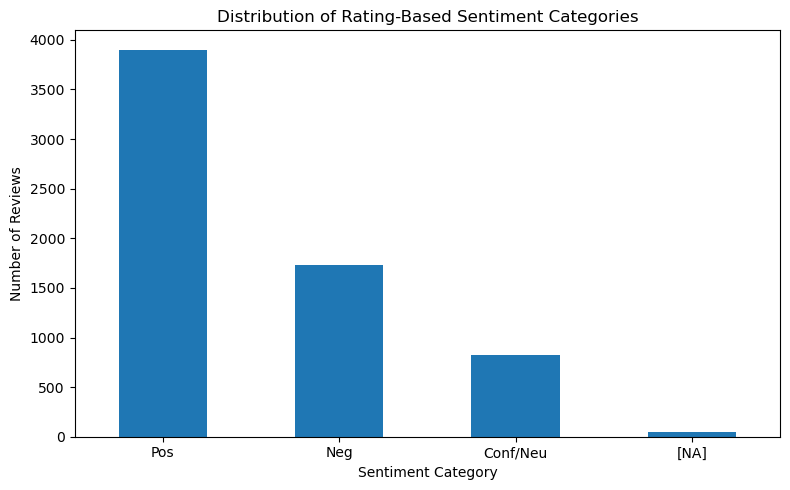

In [61]:
df_audit["rating_cat"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Rating-Based Sentiment Categories")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../07_Figures/Figure1_Sentiment.png", dpi=300)
plt.show()

In [63]:
review_type_table = pd.DataFrame({
    "Frequency": df_audit["type"].value_counts(),
    "Percentage": (
        df_audit["type"].value_counts(normalize=True) * 100
    ).round(2)
})

display(review_type_table)

,Frequency,Percentage
type,,
teacher review,3000,46.15
course review,3000,46.15
university review,500,7.69


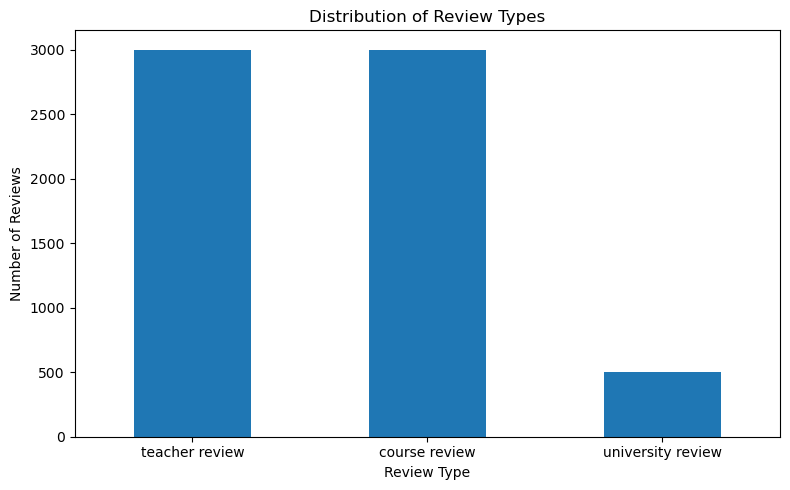

In [65]:
df_audit["type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Review Types")
plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../07_Figures/Figure2_ReviewTypes.png", dpi=300)
plt.show()

In [67]:
df_audit["character_count"] = (
    df_audit["review_text"].fillna("").str.len()
)

df_audit["word_count"] = (
    df_audit["review_text"].fillna("").str.split().str.len()
)

display(
    df_audit[
        ["character_count", "word_count", "num_token"]
    ].describe().round(2)
)

,character_count,word_count,num_token
count,6500.00,6500.00,6500.00
mean,220.94,39.63,45.29
std,182.34,32.71,37.09
min,2.00,1.00,1.00
25%,95.00,17.00,19.00
50%,192.00,34.00,40.00
75%,315.00,56.25,64.00
max,2508.00,437.00,512.00


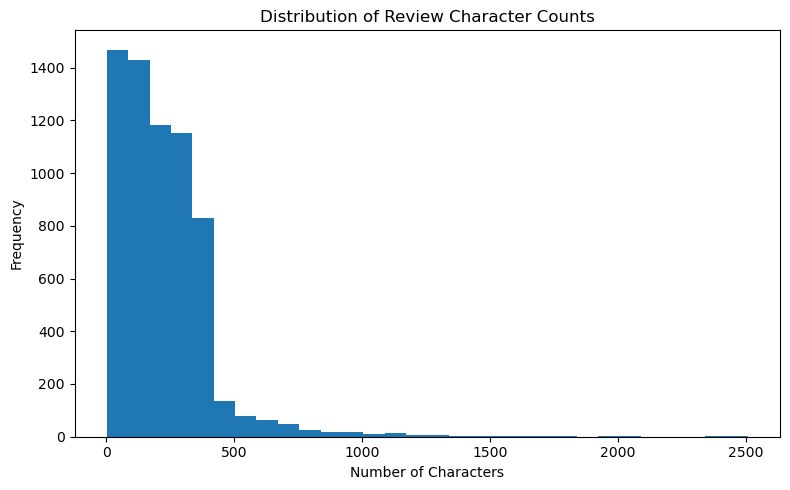

In [69]:
plt.figure(figsize=(8, 5))

plt.hist(df_audit["character_count"], bins=30)

plt.title("Distribution of Review Character Counts")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("../07_Figures/Figure3_Characters.png", dpi=300)
plt.show()

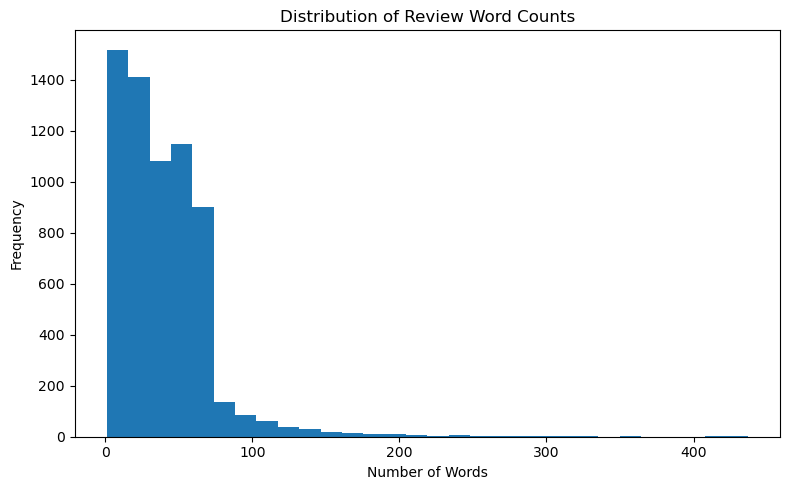

In [71]:
plt.figure(figsize=(8, 5))

plt.hist(df_audit["word_count"], bins=30)

plt.title("Distribution of Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("../07_Figures/Figure4_Words.png", dpi=300)
plt.show()

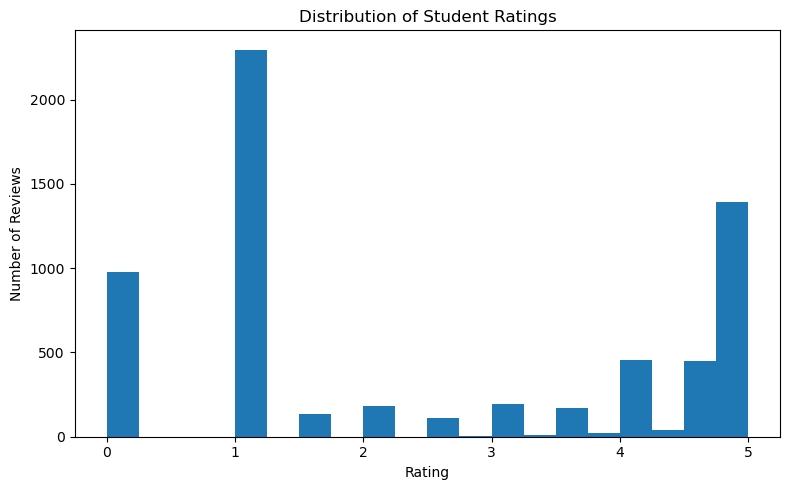

In [73]:
plt.figure(figsize=(8, 5))

plt.hist(df_audit["rating"].dropna(), bins=20)

plt.title("Distribution of Student Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig("../07_Figures/Figure5_Ratings.png", dpi=300)
plt.show()

In [75]:
counts = df_audit["rating_cat"].value_counts()

print("Largest class:", counts.idxmax(), counts.max())
print("Smallest class:", counts.idxmin(), counts.min())

print(
    "Largest-to-smallest class ratio:",
    round(counts.max() / counts.min(), 2)
)

Largest class: Pos 3901
Smallest class: [NA] 45
Largest-to-smallest class ratio: 86.69


In [77]:
print(df_audit["rating_cat"].unique())

['Pos' 'Neg' 'Conf/Neu' '[NA]']


In [79]:
selected_labels = ["Pos", "Conf/Neu", "Neg"]

samples = []

for label in selected_labels:
    subset = df_audit[df_audit["rating_cat"] == label]

    sample = subset.sample(
        n=20,
        random_state=42
    )

    samples.append(sample)

manual_reviews = pd.concat(samples)

display(
    manual_reviews[
        ["id", "rating_cat", "rating", "review_text"]
    ]
)

,id,rating_cat,rating,review_text
1850,1_83_2470_12673,Pos,5.0,I highly recommend taking this class if you are a freshmen. The lectures are once a week and you are required to obs...
5245,2_10110_1185,Pos,1.0,Say good bye to your grades for this course! I feel Chong makes this course harder than it should be his slides/anno...
3615,2_3107_168,Pos,1.0,"If you did well in Calc 1, you'll do well in Calc 2"
6006,3_171_510_271,Pos,4.4,"Great uni, nice societies , good lecturers"
3206,2_11646_782,Pos,1.0,This course has got issues. I'm not going to lie. It's basically an overview of all of the brain modeling techniques...
2620,1_206_2298_15373,Pos,4.5,She knows her terms inside and out and has really cute strories. I only wish I had the full experience that I paid f...
2555,1_221_2532_13799,Pos,4.5,Dr. Howe was informative and friendly. He made philosophy understandable.
2319,1_38_161_6286,Pos,4.5,great anatomy teacher. i highly recommend him to anyone who has to take human anatomy or cadaver. he knows exactly w...
645,1_177_1676_14109,Pos,5.0,AWSOME !!!
1914,1_182_1038_11422,Pos,5.0,"Mr. Piccone\'s one of the coolest, laid back professors I\'ve ever had. I had him for Music Appreciation during the ..."


In [81]:
# Create a separate working copy
manual_audit = manual_reviews.copy()

# Add columns for manual inspection
manual_audit["Manual_Category"] = ""
manual_audit["Difficulty_Type"] = ""
manual_audit["Explanation"] = ""

# Select important columns
manual_audit = manual_audit[
    [
        "id",
        "rating_cat",
        "rating",
        "review_text",
        "Manual_Category",
        "Difficulty_Type",
        "Explanation"
    ]
]

display(manual_audit.head())

,id,rating_cat,rating,review_text,Manual_Category,Difficulty_Type,Explanation
1850,1_83_2470_12673,Pos,5.0,I highly recommend taking this class if you are a freshmen. The lectures are once a week and you are required to obs...,,,
5245,2_10110_1185,Pos,1.0,Say good bye to your grades for this course! I feel Chong makes this course harder than it should be his slides/anno...,,,
3615,2_3107_168,Pos,1.0,"If you did well in Calc 1, you'll do well in Calc 2",,,
6006,3_171_510_271,Pos,4.4,"Great uni, nice societies , good lecturers",,,
3206,2_11646_782,Pos,1.0,This course has got issues. I'm not going to lie. It's basically an overview of all of the brain modeling techniques...,,,


In [83]:
pd.set_option("display.max_colwidth", None)

display(
    manual_audit[
        ["id", "rating_cat", "rating", "review_text"]
    ]
)

,id,rating_cat,rating,review_text
1850,1_83_2470_12673,Pos,5.0,I highly recommend taking this class if you are a freshmen. The lectures are once a week and you are required to observe at a school site for 45 hours. I did 4 hours a week and it was very simple. Mrs. Schlievert is a very easy going professor she had lectures that were conversational. We always got out early and I learned a lot. Overall easy A.
5245,2_10110_1185,Pos,1.0,Say good bye to your grades for this course! I feel Chong makes this course harder than it should be his slides/annotation were all over the place. I had to more often than not teach myself the course through websites and the text book. That being said despite being taught by Chong I liked the course a lot.
3615,2_3107_168,Pos,1.0,"If you did well in Calc 1, you'll do well in Calc 2"
6006,3_171_510_271,Pos,4.4,"Great uni, nice societies , good lecturers"
3206,2_11646_782,Pos,1.0,"This course has got issues. I'm not going to lie. It's basically an overview of all of the brain modeling techniques in the past. For me, that's exactly what I wanted. For everyone else, this might be hell. One huge problem with the course is it's mostly just humongous walls of text. If you're a visual learner, this is basically just a giant ""fuck you"". Also the assigned reading are basically useless. On the bright side, it is really easy. All you need to do is write essays."
2620,1_206_2298_15373,Pos,4.5,"She knows her terms inside and out and has really cute strories. I only wish I had the full experience that I paid for. I was in a 4hr Saturday class which lasted 5 weeks. She didn\'t show to 2 of the classes. This is an easy ""A"" class but come on! I wish I could get a pay check for showing up to 3/5 classes."
2555,1_221_2532_13799,Pos,4.5,Dr. Howe was informative and friendly. He made philosophy understandable.
2319,1_38_161_6286,Pos,4.5,great anatomy teacher. i highly recommend him to anyone who has to take human anatomy or cadaver. he knows exactly what he is talking about and is funny/kind/understanding. the tests are veerrrry fair as long as you review the notes/book
645,1_177_1676_14109,Pos,5.0,AWSOME !!!
1914,1_182_1038_11422,Pos,5.0,"Mr. Piccone\'s one of the coolest, laid back professors I\'ve ever had. I had him for Music Appreciation during the Winter. He\'s real easy to talk to and I never saw him lose his composure. I\'d take him again if I had to. I highly recommend him"


In [87]:
manual_audit = manual_reviews[
    ["id", "rating_cat", "rating", "review_text"]
].copy()

manual_audit["manual_sentiment"] = ""
manual_audit["observation_type"] = ""
manual_audit["reason"] = ""

manual_audit.to_excel(
    "../06_Results/Week2_Manual_Inspection.xlsx",
    index=False
)

print("Excel file successfully saved!")

Excel file successfully saved!
